In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

In [3]:
data = pd.read_csv('/content/drive/MyDrive/coffee_beans_dataset/coffee_roasting_dataset.csv')
print(data.shape)

(200, 3)


In [4]:
data.head()

,temperature_celsius,duration_minutes,good_roast
0,185.317638,12.693965,1
1,259.920475,11.867664,0
2,231.013571,14.414242,0
3,175.366645,11.720587,0
4,187.120865,14.129732,1


In [5]:
X_train = data[['temperature_celsius' , 'duration_minutes']]
print(X_train.head())
print(X_train.shape)
print(type(X_train))

   temperature_celsius  duration_minutes
0           185.317638         12.693965
1           259.920475         11.867664
2           231.013571         14.414242
3           175.366645         11.720587
4           187.120865         14.129732
(200, 2)
<class 'pandas.core.frame.DataFrame'>


In [6]:
y_train = data[['good_roast']]
print(y_train.head())
print(y_train.shape)

   good_roast
0           1
1           0
2           0
3           0
4           1
(200, 1)


In [7]:
# converting data from paandas dataframes to numpy array
X_train = data[['temperature_celsius' , 'duration_minutes']]
X_train = X_train.to_numpy()
# print(X_train.head())
print(X_train.shape)
print(type(X_train))
print(X_train[:10])

(200, 2)
<class 'numpy.ndarray'>
[[185.31763812  12.69396457]
 [259.92047498  11.86766377]
 [231.01357101  14.41424211]
 [175.3666449   11.72058651]
 [187.12086467  14.12973206]
 [225.90586448  12.10024905]
 [208.40515676  14.17718919]
 [207.07593089  14.0327376 ]
 [280.60385359  14.23225929]
 [202.86935247  12.24901028]]


In [8]:
y_train = data[['good_roast']]
y_train = y_train.to_numpy()
print(y_train[:10])
print(y_train.shape)

[[1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]]
(200, 1)


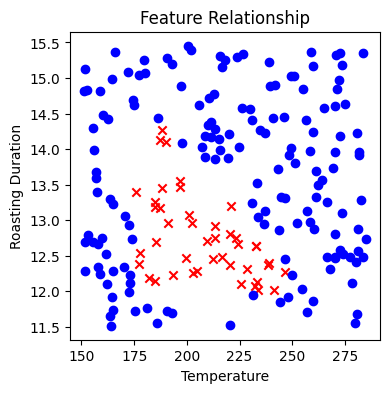

In [9]:
pos = (y_train.ravel()==1)
neg = (y_train.ravel()==0)
fig, ax = plt.subplots(1,1, figsize=(4,4))
ax.scatter(X_train[pos , 0], X_train[pos , 1], label = 'Good roast', marker='x', c='r')
ax.scatter(X_train[neg , 0], X_train[neg , 1], marker='o', c='b', label='Bad roast')
ax.set_xlabel("Temperature")
ax.set_ylabel("Roasting Duration")
ax.set_title("Feature Relationship")
plt.show()


In [10]:
a = np.array([[10, 20],
              [30, 40],
              [50, 60]])
print(a.shape)

a = np.array([[10, 20],
              [30, 40],
              [50, 60]])

a = a.ravel()
print(a)
print(a.shape)

(3, 2)
[10 20 30 40 50 60]
(6,)


In [11]:
# Data analysis

print(f"Max, min : {np.max(X_train[: , 0]):0.2f}, {np.min(X_train[: , 0]):0.2f}")
print(f"Max, min : {np.max(X_train[: , 1])}, {np.min(X_train[: , 1])}")

Max, min : 284.99, 151.32
Max, min : 15.45420693, 11.51274708


In [12]:
# normalization

norm_1 = tf.keras.layers.Normalization(axis=-1)
norm_1.adapt(X_train)
X_normed = norm_1(X_train)

In [13]:
# repeating dataset

Xt = np.tile(X_normed, (1000, 1))
Yt = np.tile(y_train, (1000, 1))

print(Xt.shape)
print(Yt.shape)

(200000, 2)
(200000, 1)


In [14]:
model = Sequential([
    tf.keras.layers.Dense(units=3 , activation='sigmoid'),
    tf.keras.layers.Dense(units=1, activation='sigmoid')
])

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
model = Sequential([
    tf.keras.Input(shape=(2,)),
    tf.keras.layers.Dense(units=3 , activation='sigmoid', name = 'Layer_1'),
    tf.keras.layers.Dense(units=1, activation='sigmoid', name='Layer_2')
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Layer_1 (Dense)                 │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer_2 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
w1 , b1 = model.get_layer('Layer_1').get_weights()
print(f"W1: {w1}")
print(f"b1: {b1}")

print(f"W1: {w1.shape}")
print(f"b1: {b1.shape}")

w2, b2 = model.get_layer('Layer_2').get_weights()
print(f"W2: {w2}")
print(f"b2: {b2}")

print(f"W2: {w2.shape}")
print(f"b2: {b2.shape}")

W1: [[-0.02404106  0.37347162 -0.2650143 ]
 [ 0.94542027 -0.10361993  0.60068405]]
b1: [0. 0. 0.]
W1: (2, 3)
b1: (3,)
W2: [[-0.6597474]
 [-0.5170727]
 [-1.0297723]]
b2: [0.]
W2: (3, 1)
b2: (1,)


In [18]:
model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
)

history = model.fit(
    X_normed, y_train, epochs=10
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4931  
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4866 
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4817 
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4780 
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4745 
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4707 
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4667 
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4634 
Epoch 9/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4597 
Epoch 10/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4567 


In [26]:
w1 , b1 = model.get_layer('Layer_1').get_weights()
print(f"W1: {w1}")
print(f"b1: {b1}")

print(f"W1: {w1.shape}")
print(f"b1: {b1.shape}")

w2, b2 = model.get_layer('Layer_2').get_weights()
print(f"W2: {w2}")
print(f"b2: {b2}")

print(f"W2: {w2.shape}")
print(f"b2: {b2.shape}")

W1: [[0.4115614  0.71700597 0.08359657]
 [1.4607079  0.40520746 1.0865145 ]]
b1: [-0.11884762 -0.06612084 -0.05990523]
W1: (2, 3)
b1: (3,)
W2: [[-0.9908815]
 [-0.6414814]
 [-1.2386736]]
b2: [-0.02337893]
W2: (3, 1)
b2: (1,)


Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4931  


Epoch 1/10 : represent number of epoch running.
7/7 is the batch. by default, tensorflow batch size is 32. so we have total 200 examples.
so, there will be 200/32 , is 6.25, approximately . so there are 7 batches in this case. where 6 batches contains 32 examples each , and 1 final batch has 8 examples.

In [20]:
print(history)

In [19]:
print(history.history)

{'loss': [0.4931212365627289, 0.4865850806236267, 0.4817304313182831, 0.47804415225982666, 0.47451063990592957, 0.47068414092063904, 0.46665650606155396, 0.4634290933609009, 0.45970138907432556, 0.45666953921318054]}


In [25]:
print(history.history['loss'][:3])

[0.4931212365627289, 0.4865850806236267, 0.4817304313182831]


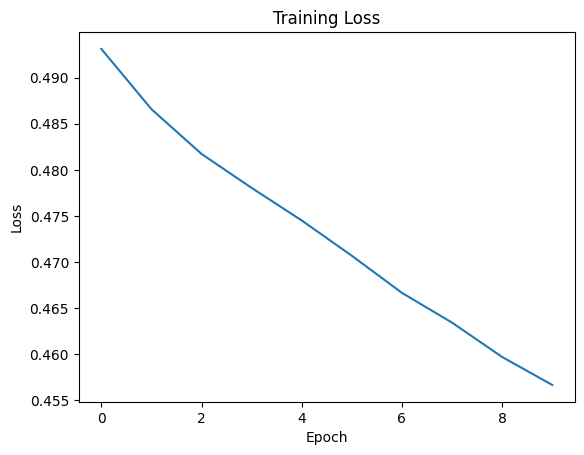

In [22]:
plt.plot(history.history['loss'])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

In [27]:
w1 , b1 = model.get_layer('Layer_1').get_weights()
print(f"W1: {w1}")
print(f"b1: {b1}")

print(f"W1: {w1.shape}")
print(f"b1: {b1.shape}")

w2, b2 = model.get_layer('Layer_2').get_weights()
print(f"W2: {w2}")
print(f"b2: {b2}")

print(f"W2: {w2.shape}")
print(f"b2: {b2.shape}")

# now set these updated weightzs

W1: [[0.4115614  0.71700597 0.08359657]
 [1.4607079  0.40520746 1.0865145 ]]
b1: [-0.11884762 -0.06612084 -0.05990523]
W1: (2, 3)
b1: (3,)
W2: [[-0.9908815]
 [-0.6414814]
 [-1.2386736]]
b2: [-0.02337893]
W2: (3, 1)
b2: (1,)


In [28]:
model.get_layer('Layer_1').set_weights([w1,b1])
model.get_layer('Layer_2').set_weights([w2,b2])

In [31]:
w1, b1 = model.get_layer('Layer_1').get_weights()
w2, b2 = model.get_layer('Layer_2').get_weights()

print(f"W1: {w1}")
print(f"b1: {b1}")

# print(f"W1: {w1.shape}")
# print(f"b1: {b1.shape}")

print(f"W2: {w2}")
print(f"b2: {b2}")

# print(f"W2: {w2.shape}")
# print(f"b2: {b2.shape}")

W1: [[0.4115614  0.71700597 0.08359657]
 [1.4607079  0.40520746 1.0865145 ]]
b1: [-0.11884762 -0.06612084 -0.05990523]
W2: [[-0.9908815]
 [-0.6414814]
 [-1.2386736]]
b2: [-0.02337893]


In [32]:
# test
x_test = np.array([
    [200,13.9],
    [200 , 17]
])

x_test_normed = norm_1(x_test)

prediction = model.predict(x_test_normed)
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step
[[0.16758548]
 [0.06593923]]
